In [1]:
!pip install -q pandas numpy matplotlib seaborn openpyxl

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import io

uploaded = files.upload()

# Read the uploaded CSV or Excel file
file_name = next(iter(uploaded))

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))
elif file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
else:
    raise ValueError("Please upload a CSV or Excel file.")

# Keep the original data unchanged
original_df = df.copy()
df = original_df.copy()

print("Dataset loaded successfully!")
print("File name:", file_name)
print("Dataset shape:", df.shape)

display(df.head())

Saving AB_NYC_2019.csv to AB_NYC_2019 (1).csv
Dataset loaded successfully!
File name: AB_NYC_2019 (1).csv
Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows: 48895
Number of columns: 16

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
d

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,48895.0,NaN,NaN,NaN,19017143.23618,10983108.38561,2539.0,9471945.0,19677284.0,29152178.5,36487245.0
name,48879,47905,Hillside Hotel,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,48895.0,NaN,NaN,NaN,67620010.64661,78610967.032667,2438.0,7822033.0,30793816.0,107434423.0,274321313.0
host_name,48874,11452,Michael,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,48895,5,Manhattan,21661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,48895,221,Williamsburg,3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,48895.0,NaN,NaN,NaN,40.728949,0.05453,40.49979,40.6901,40.72307,40.763115,40.91306
longitude,48895.0,NaN,NaN,NaN,-73.95217,0.046157,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299
room_type,48895,3,Entire home/apt,25409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,48895.0,NaN,NaN,NaN,152.720687,240.15417,0.0,69.0,106.0,175.0,10000.0


In [4]:
missing_count = df.isna().sum()

missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": missing_count.values,
    "Missing_Percentage": (
        df.isna().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Count", ascending=False
)

display(missing_report)

print("Total missing cells:", int(df.isna().sum().sum()))

,Column,Missing_Count,Missing_Percentage
12,last_review,10052,20.56
13,reviews_per_month,10052,20.56
3,host_name,21,0.04
1,name,16,0.03
4,neighbourhood_group,0,0.00
5,neighbourhood,0,0.00
0,id,0,0.00
2,host_id,0,0.00
7,longitude,0,0.00
6,latitude,0,0.00


Total missing cells: 20141


In [5]:
duplicate_mask = df.duplicated()

print("Duplicate rows:", int(duplicate_mask.sum()))

print("\nDuplicate records:")
display(df[duplicate_mask].head(20))

Duplicate rows: 0

Duplicate records:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


In [6]:
# Change Customer_ID to a real column name in your dataset
if "Customer_ID" in df.columns:
    print(
        "Repeated customer IDs:",
        int(df.duplicated(subset=["Customer_ID"]).sum())
    )

In [7]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

outlier_results = []

for column in numeric_columns:
    values = df[column].dropna()

    if len(values) < 4:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        continue

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    mask = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).fillna(False)

    outlier_results.append({
        "Column": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Outlier_Count": int(mask.sum())
    })

outlier_report = pd.DataFrame(outlier_results)

if outlier_report.empty:
    print("No outliers were evaluated.")
else:
    display(outlier_report)

,Column,Lower_Limit,Upper_Limit,Outlier_Count
0,id,-2.004841e+07,5.867253e+07,0
1,host_id,-1.415966e+08,2.568530e+08,1526
2,latitude,4.058058e+01,4.087264e+01,425
3,longitude,-7.405326e+01,-7.386608e+01,2833
4,price,-9.000000e+01,3.340000e+02,2972
5,minimum_nights,-5.000000e+00,1.100000e+01,6607
6,number_of_reviews,-3.350000e+01,5.850000e+01,6021
7,reviews_per_month,-2.555000e+00,4.765000e+00,1793
8,calculated_host_listings_count,-5.000000e-01,3.500000e+00,7081
9,availability_365,-3.405000e+02,5.675000e+02,0


In [8]:
if "Age" in df.columns:
    age = pd.to_numeric(df["Age"], errors="coerce")

    invalid_age_mask = age < 0

    print(
        "Invalid negative ages:",
        int(invalid_age_mask.sum())
    )

    display(df.loc[invalid_age_mask])
else:
    print(
        "No Age column found. "
        "Define a rule for one of your dataset's columns."
    )

No Age column found. Define a rule for one of your dataset's columns.


In [9]:
issues = []

# Missing values
for column in df.columns:
    count = int(df[column].isna().sum())

    if count > 0:
        issues.append({
            "Issue": "Missing values",
            "Column": column,
            "Count": count,
            "Possible_Cause":
                "Missing source data or an upstream transformation",
            "Suggested_Action":
                "Inspect source records before filling or removing values"
        })

# Exact duplicate rows
duplicate_count = int(df.duplicated().sum())

if duplicate_count > 0:
    issues.append({
        "Issue": "Duplicate rows",
        "Column": "All columns",
        "Count": duplicate_count,
        "Possible_Cause":
            "Repeated source records or duplicated pipeline loads",
        "Suggested_Action":
            "Verify business keys and load history"
    })

# Outliers
if not outlier_report.empty:
    for _, row in outlier_report.iterrows():
        count = int(row["Outlier_Count"])

        if count > 0:
            issues.append({
                "Issue": "Potential outliers",
                "Column": row["Column"],
                "Count": count,
                "Possible_Cause":
                    "Extreme values, data-entry errors or unit differences",
                "Suggested_Action":
                    "Inspect flagged values against business expectations"
            })

# Negative age business rule
if "Age" in df.columns:
    age = pd.to_numeric(df["Age"], errors="coerce")
    invalid_count = int((age < 0).sum())

    if invalid_count > 0:
        issues.append({
            "Issue": "Invalid age",
            "Column": "Age",
            "Count": invalid_count,
            "Possible_Cause":
                "Possible entry or transformation error",
            "Suggested_Action":
                "Verify the original record and correct only with evidence"
        })

issue_report = pd.DataFrame(
    issues,
    columns=[
        "Issue", "Column", "Count",
        "Possible_Cause", "Suggested_Action"
    ]
)

if issue_report.empty:
    print("No issues found by the checks implemented.")
else:
    display(issue_report)

,Issue,Column,Count,Possible_Cause,Suggested_Action
0,Missing values,name,16,Missing source data or an upstream transformation,Inspect source records before filling or remov...
1,Missing values,host_name,21,Missing source data or an upstream transformation,Inspect source records before filling or remov...
2,Missing values,last_review,10052,Missing source data or an upstream transformation,Inspect source records before filling or remov...
3,Missing values,reviews_per_month,10052,Missing source data or an upstream transformation,Inspect source records before filling or remov...
4,Potential outliers,host_id,1526,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...
5,Potential outliers,latitude,425,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...
6,Potential outliers,longitude,2833,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...
7,Potential outliers,price,2972,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...
8,Potential outliers,minimum_nights,6607,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...
9,Potential outliers,number_of_reviews,6021,"Extreme values, data-entry errors or unit diff...",Inspect flagged values against business expect...


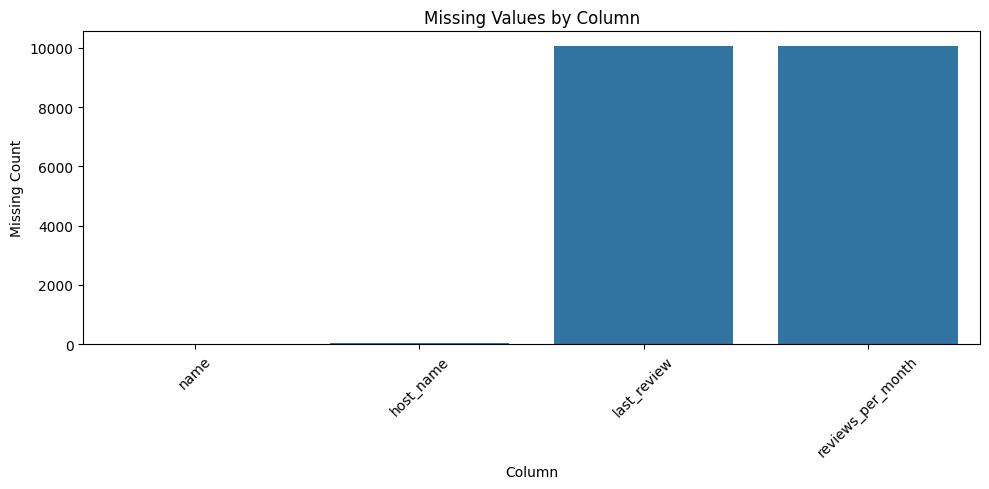

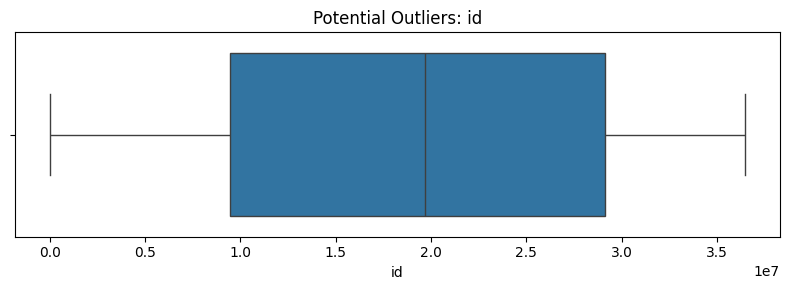

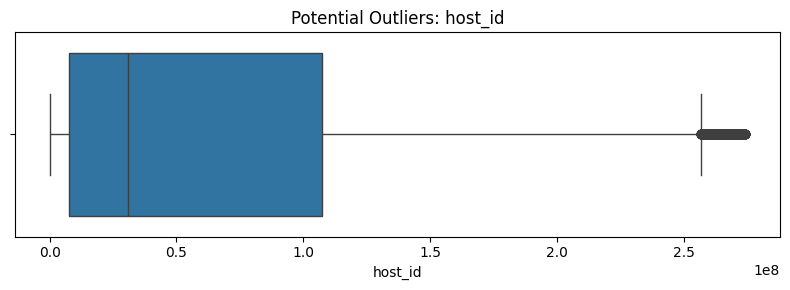

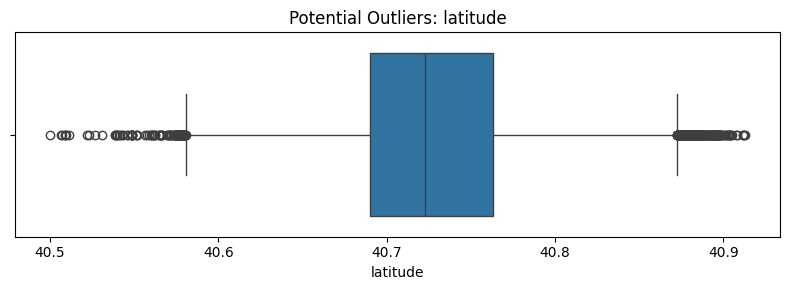

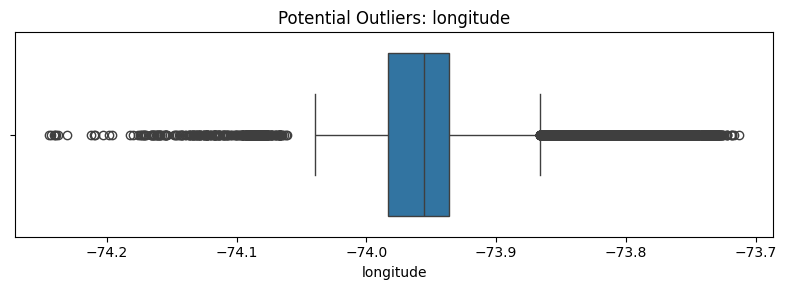

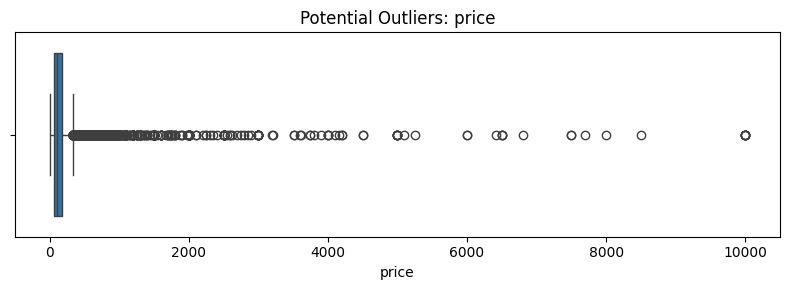

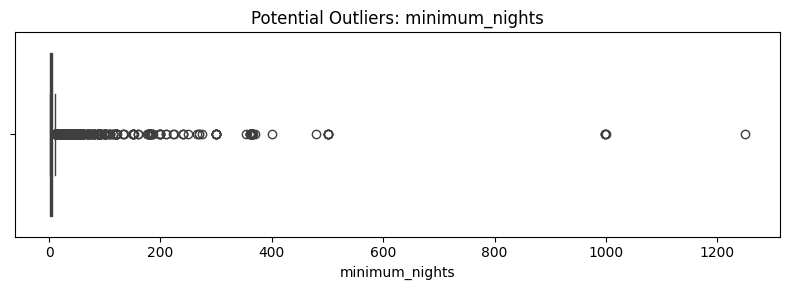

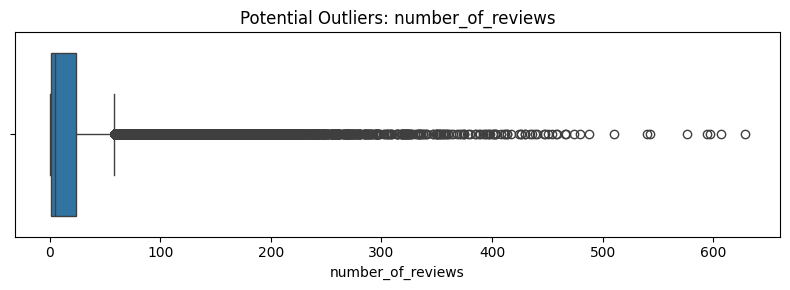

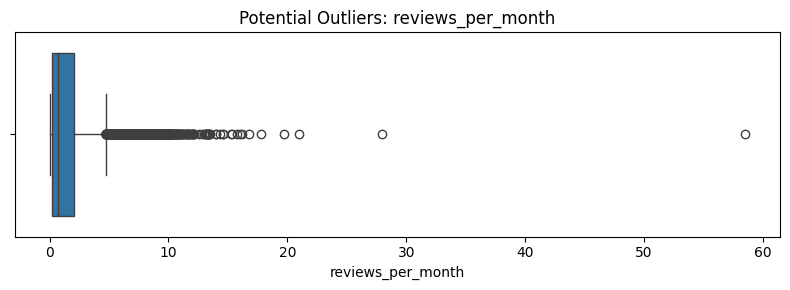

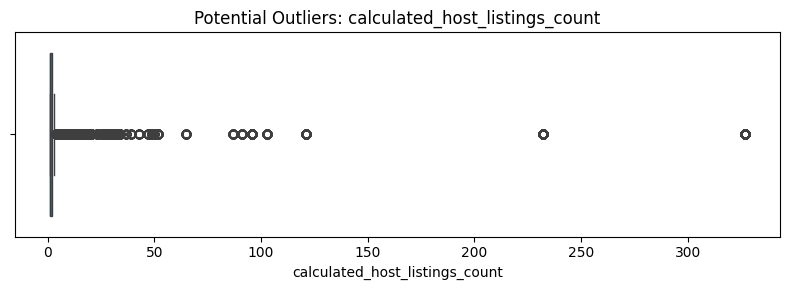

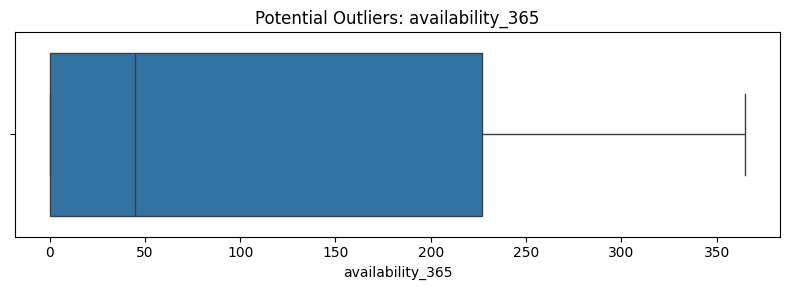

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Missing values by column
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

if not missing_counts.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values
    )
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values to visualize.")

# Boxplots for numeric columns
for column in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Potential Outliers: {column}")
    plt.tight_layout()
    plt.show()

In [11]:
import re

sample_logs = """
2026-10-29 09:00:00 INFO Pipeline started
2026-10-29 09:01:00 ERROR Missing column Customer_ID
2026-10-29 09:02:00 ERROR Invalid format while casting Age
2026-10-29 09:03:00 ERROR Database connection timeout
"""

patterns = {
    "Schema issue": r"missing column|schema",
    "Data format issue": r"invalid format|cast|typeerror",
    "Connection issue": r"connection|timeout",
    "Pipeline failure": r"error|exception|failed"
}

log_findings = []

for line_number, line in enumerate(
    sample_logs.strip().splitlines(), start=1
):
    for category, pattern in patterns.items():
        if re.search(pattern, line, re.IGNORECASE):
            log_findings.append({
                "Line": line_number,
                "Category": category,
                "Message": line.strip()
            })
            break

log_report = pd.DataFrame(log_findings)
display(log_report)

,Line,Category,Message
0,2,Schema issue,2026-10-29 09:01:00 ERROR Missing column Custo...
1,3,Data format issue,2026-10-29 09:02:00 ERROR Invalid format while...
2,4,Connection issue,2026-10-29 09:03:00 ERROR Database connection ...


In [12]:
from google.colab import files

# Export data-quality findings
issue_report.to_csv(
    "data_quality_report.csv",
    index=False
)

# Export profiling report
profile_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": [str(df[c].dtype) for c in df.columns],
    "Missing_Count": [int(df[c].isna().sum()) for c in df.columns],
    "Unique_Count": [int(df[c].nunique(dropna=True)) for c in df.columns]
})

profile_report.to_csv(
    "data_profile_report.csv",
    index=False
)

files.download("data_quality_report.csv")
files.download("data_profile_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>